# 04 · Gesamtvergleich: Welche Methode findet die Suva-Fälle am besten?

Alle Varianten des Teams mit **demselben Messverfahren** in einer Tabelle:

| Achse | Varianten |
|---|---|
| **Stufe 1** (gratis, jedes Urteil) | Ähnlichkeit zu Suva-Fällen (heute, Vector-DB) · Gelernter Score (Notebook 03) – jeweils **roh** oder **zentriert** (Mittelwertvektor abgezogen, Notebook 02) |
| **Stufe 2** (Apertus, Teilmenge) | keine · 8B mit heutigem Triage-Prompt (v1) · 8B mit Prompt v2 · **70B mit zwei Durchgängen und Kalibrierung (Abi, #62)** · **dasselbe im Thinking-Mode** (`--model apertus-v1-5-70b-thinking`) |

**Messverfahren wie Abis `eval/relevance_eval.py`:** zwei Quartale mit Suva-Labels (Q4/2025, Q1/2026, zusammen **59 Suva-Fälle**).
Jedes Quartal wird nur mit Wissen aus dem **anderen** Quartal bewertet (Referenzen, Training, Kalibrierung), dann werden beide Quartale zusammengezählt.
Ist eine Stufe 2 dabei, werden die von Apertus bewerteten Urteile nach dem Mittel der beiden Ränge (50/50) sortiert, alle übrigen folgen in der Reihenfolge von Stufe 1.

Rechenlogik: `src/hack_apertus_coffee_exe/eval/compare.py` (Tests: `tests/test_eval_compare.py`). Das Notebook ruft kein Modell auf, es liest gespeicherte Antworten.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.compare import (
    FOLDS, STAGE1, abi_two_pass, apertus_8b, external_scores, fold_metrics, recall_curve_pooled, run_grid,
)
from hack_apertus_coffee_exe.eval.relevance import Corpus, open_vectordb

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)
# Kategorische Farben in fester Reihenfolge, grau = heutiger Stand
GRAY, C1, C2, C3, C4, INK = "#9c9c9c", "#257de0", "#f47230", "#00b894", "#6a4ce2", "#191919"

corpus = Corpus(open_vectordb())

# Thinking-Mode: Abis Pipeline mit dem Reasoning-Modell, Ergebnisse in einem eigenen Ordner:
#   python -m hack_apertus_coffee_exe.triage.cli relevance --period 2026-Q1 --label-periods 2025-Q4 2026-Q1 #       --model apertus-v1-5-70b-thinking --tables-dir results/tables/thinking_70b --no-export
THINKING_DIR = Path("results/tables/thinking_70b")

In [2]:
stage2 = {
    "keine": None,
    "8B v1 (heutiger Prompt)": lambda f: apertus_8b("v1", f),
    "8B v2": lambda f: apertus_8b("v2", f),
    "70B zwei Durchgänge (Abi)": lambda f: abi_two_pass(corpus, f),
}
if all((THINKING_DIR / f"relevance_scores_{f.name.split('-')[1].lower()}_{f.name.split('-')[0]}.json").exists() for f in FOLDS):
    stage2["70B Thinking zwei Durchgänge"] = lambda f: abi_two_pass(corpus, f, tables_dir=THINKING_DIR)
else:
    print("Thinking-Mode: Ergebnisse in", THINKING_DIR, "fehlen noch, Spalte fehlt.")

grid, rankings = run_grid(corpus, stage2)
grid.to_csv("results/tables/gesamtvergleich_relevanz.csv", index=False)
print(f"{len(grid)} Varianten gemessen, Tabelle: results/tables/gesamtvergleich_relevanz.csv")

24 Varianten gemessen, Tabelle: results/tables/gesamtvergleich_relevanz.csv


## 1. Wie viel Apertus kostet jede Stufe 2?

Apertus-Aufrufe pro Quartal (gemittelt über beide Quartale). 8B bewertet eine Vorauswahl (Top 200 jeder Stufe-1-Variante),
Abis Variante liest alle Urteile zur Unfall-, Invaliden- und Militärversicherung der III./IV. öffentlich-rechtlichen Abteilung **vollständig** und fragt bei Bedarf ein zweites Mal nach.


In [3]:
def abi_calls(name, tables_dir=Path("results/tables")):
    year, q = name.split("-")
    records = json.loads((tables_dir / f"relevance_scores_{q.lower()}_{year}.json").read_text(encoding="utf-8"))
    return sum(bool(r.get("triage")) for r in records) + sum(bool(r.get("deep")) for r in records)

models = ["–", "apertus-v1-5-8b", "apertus-v1-5-8b", "apertus-v1-5-70b"]
calls = [0, np.mean([len(apertus_8b("v1", f)) for f in FOLDS]), np.mean([len(apertus_8b("v2", f)) for f in FOLDS]),
         np.mean([abi_calls(f.name) for f in FOLDS])]
if "70B Thinking zwei Durchgänge" in stage2:
    models.append("apertus-v1-5-70b-thinking")
    calls.append(np.mean([abi_calls(f.name, THINKING_DIR) for f in FOLDS]))
costs = pd.DataFrame({"Modell": models, "Aufrufe pro Quartal": calls}, index=list(stage2)).round(0)
costs

,Modell,Aufrufe pro Quartal
keine,–,0.0
8B v1 (heutiger Prompt),apertus-v1-5-8b,264.0
8B v2,apertus-v1-5-8b,264.0
70B zwei Durchgänge (Abi),apertus-v1-5-70b,260.0
70B Thinking zwei Durchgänge,apertus-v1-5-70b-thinking,260.0


## 2. Die Gesamttabelle

**Spalten** (beide Quartale zusammen, 59 Suva-Fälle)
- **Top 30 je Quartal:** So viele Suva-Fälle stehen unter den ersten 30 jedes Quartals (Erfolgskriterium der Challenge). Höher ist besser, das Maximum ist 59.
- **Recall Top 50 / Top 100:** Anteil der Suva-Fälle unter den ersten 50 bzw. 100 jedes Quartals.
- **Listenlänge für 90 % / 100 % Recall:** So viele Urteile (beide Quartale zusammen) müsste Suva lesen, um 90 % bzw. alle Suva-Fälle zu finden. Tiefer ist besser.


In [4]:
METRICS = ["Top 30 je Quartal (von 59)", "Recall Top 50", "Recall Top 100",
           "Listenlänge für 90 % Recall", "Listenlänge für 100 % Recall"]
table = grid.set_index(["Stufe 1", "Stufe 2"])[METRICS]
(table.style
 .format({"Recall Top 50": "{:.0%}", "Recall Top 100": "{:.0%}"})
 .background_gradient(cmap="Blues", subset=["Top 30 je Quartal (von 59)", "Recall Top 50", "Recall Top 100"])
 .background_gradient(cmap="Blues_r", subset=["Listenlänge für 90 % Recall", "Listenlänge für 100 % Recall"]))

## 3. Auf einen Blick: zwei Kennzahlen als Matrix

Zeilen = Stufe 1, Spalten = Stufe 2. Dunkler ist besser.


In [5]:
def matrix(metric):
    m = grid.pivot(index="Stufe 1", columns="Stufe 2", values=metric)
    return m.reindex(index=[*STAGE1, "nur Stufe 2"], columns=list(stage2))

print("Suva-Fälle in den Top 30 je Quartal (von 59)")
display(matrix("Top 30 je Quartal (von 59)").style.format("{:.0f}", na_rep="–").background_gradient(cmap="Blues", axis=None))
print("Listenlänge, um ALLE 59 Suva-Fälle zu finden (beide Quartale zusammen)")
display(matrix("Listenlänge für 100 % Recall").style.format("{:.0f}", na_rep="–").background_gradient(cmap="Blues_r", axis=None))

Suva-Fälle in den Top 30 je Quartal (von 59)


Stufe 2,keine,8B v1 (heutiger Prompt),8B v2,70B zwei Durchgänge (Abi),70B Thinking zwei Durchgänge
Stufe 1,,,,,
"Ähnlichkeit, roh (heute)",32,33,35,38,37
"Ähnlichkeit, zentriert",28,33,34,37,36
"Gelernt, roh",32,34,36,39,38
"Gelernt, zentriert",33,34,36,37,37
nur Stufe 2,–,33,35,38,37


Listenlänge, um ALLE 59 Suva-Fälle zu finden (beide Quartale zusammen)


Stufe 2,keine,8B v1 (heutiger Prompt),8B v2,70B zwei Durchgänge (Abi),70B Thinking zwei Durchgänge
Stufe 1,,,,,
"Ähnlichkeit, roh (heute)",2039,2044,1966,249,254
"Ähnlichkeit, zentriert",1520,1531,1517,247,247
"Gelernt, roh",484,498,422,211,191
"Gelernt, zentriert",391,424,413,206,187
nur Stufe 2,–,2044,1960,195,186


## 4. Recall-Kurven der wichtigsten Varianten

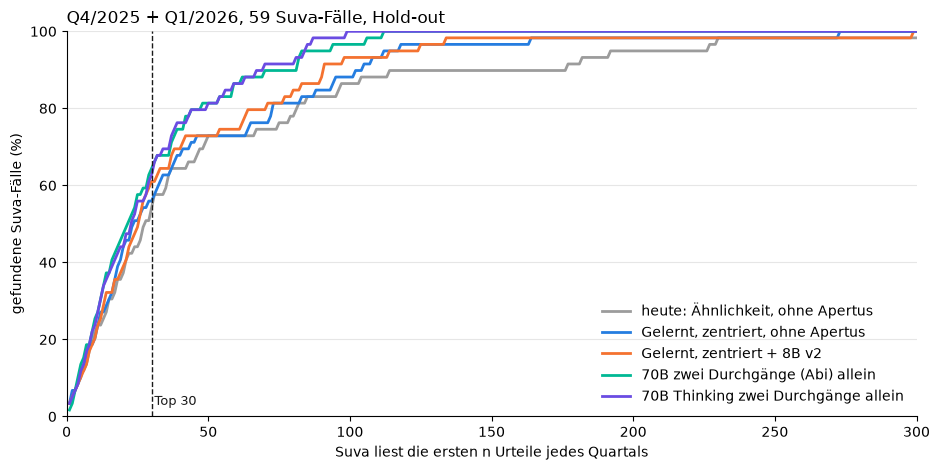

In [6]:
main = {
    "heute: Ähnlichkeit, ohne Apertus": (("Ähnlichkeit, roh (heute)", "keine"), GRAY),
    "Gelernt, zentriert, ohne Apertus": (("Gelernt, zentriert", "keine"), C1),
    "Gelernt, zentriert + 8B v2": (("Gelernt, zentriert", "8B v2"), C2),
    "70B zwei Durchgänge (Abi) allein": (("nur Stufe 2", "70B zwei Durchgänge (Abi)"), C3),
}
if "70B Thinking zwei Durchgänge" in stage2:
    main["70B Thinking zwei Durchgänge allein"] = (("nur Stufe 2", "70B Thinking zwei Durchgänge"), C4)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
for label, (key, color) in main.items():
    curve = recall_curve_pooled(rankings[key], 300)
    ax.plot(curve.index, curve.values * 100, color=color, linewidth=2, label=label)
ax.axvline(30, color=INK, linewidth=1, linestyle="--")
ax.text(31, 3, "Top 30", fontsize=9, color=INK)
ax.set_xlabel("Suva liest die ersten n Urteile jedes Quartals")
ax.set_ylabel("gefundene Suva-Fälle (%)")
ax.set_ylim(0, 100)
ax.set_xlim(0, 300)
ax.grid(axis="y", color="#e6e6e6")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Q4/2025 + Q1/2026, 59 Suva-Fälle, Hold-out", loc="left")
fig.tight_layout()
plt.show()

## 5. Roh oder zentriert? Wirkung des Mittelwertvektors

In [7]:
pairs = [("Ähnlichkeit, roh (heute)", "Ähnlichkeit, zentriert"), ("Gelernt, roh", "Gelernt, zentriert")]
rows = []
for raw, cen in pairs:
    for s2 in stage2:
        a, b = table.loc[(raw, s2)], table.loc[(cen, s2)]
        rows.append({"Stufe 1": raw.split(",")[0], "Stufe 2": s2,
                     "Top 30: roh → zentriert": f"{a.iloc[0]:.0f} → {b.iloc[0]:.0f}",
                     "Liste 90 %: roh → zentriert": f"{a.iloc[3]:.0f} → {b.iloc[3]:.0f}",
                     "Liste 100 %: roh → zentriert": f"{a.iloc[4]:.0f} → {b.iloc[4]:.0f}"})
pd.DataFrame(rows).set_index(["Stufe 1", "Stufe 2"])

Top 30: roh → zentriert  \
Stufe 1     Stufe 2                                                
Ähnlichkeit keine                                        32 → 28   
            8B v1 (heutiger Prompt)                      33 → 33   
            8B v2                                        35 → 34   
            70B zwei Durchgänge (Abi)                    38 → 37   
            70B Thinking zwei Durchgänge                 37 → 36   
Gelernt     keine                                        32 → 33   
            8B v1 (heutiger Prompt)                      34 → 34   
            8B v2                                        36 → 36   
            70B zwei Durchgänge (Abi)                    39 → 37   
            70B Thinking zwei Durchgänge                 38 → 37   

                                         Liste 90 %: roh → zentriert  \
Stufe 1     Stufe 2                                                    
Ähnlichkeit keine                                          291 → 215   
            8B v1 (heutiger Prompt)                        305 → 204   
            8B v2                                          179 → 190   
            70B zwei Durchgänge (Abi)                      153 → 151   
            70B Thinking zwei Durchgänge                   153 → 154   
Gelernt     keine                                          284 → 207   
            8B v1 (heutiger Prompt)                        288 → 214   
            8B v2                                          177 → 181   
            70B zwei Durchgänge (Abi)                      148 → 149   
            70B Thinking zwei Durchgänge                   152 → 151   

                                         Liste 100 %: roh → zentriert  
Stufe 1     Stufe 2                                                    
Ähnlichkeit keine                                         2039 → 1520  
            8B v1 (heutiger Prompt)                       2044 → 1531  
            8B v2                                         1966 → 1517  
            70B zwei Durchgänge (Abi)                       249 → 247  
            70B Thinking zwei Durchgänge                    254 → 247  
Gelernt     keine                                           484 → 391  
            8B v1 (heutiger Prompt)                         498 → 424  
            8B v2                                           422 → 413  
            70B zwei Durchgänge (Abi)                       211 → 206  
            70B Thinking zwei Durchgänge                    191 → 187

## 6. Pro Quartal (zur Kontrolle, dass ein Ergebnis nicht nur an einem Quartal hängt)

In [8]:
rows = []
for label, (key, _) in main.items():
    for fold, frame in zip(FOLDS, rankings[key]):
        m = fold_metrics(frame)
        rows.append({"Variante": label, "Quartal": fold.name, "Suva-Fälle": m["suva"], "in Top 30": m["top30"],
                     "Liste 90 %": m["len90"], "Liste 100 %": m["len100"]})
pd.DataFrame(rows).set_index(["Variante", "Quartal"])

Suva-Fälle  in Top 30  \
Variante                            Quartal                          
heute: Ähnlichkeit, ohne Apertus    2025-Q4          28         17   
                                    2026-Q1          31         15   
Gelernt, zentriert, ohne Apertus    2025-Q4          28         19   
                                    2026-Q1          31         14   
Gelernt, zentriert + 8B v2          2025-Q4          28         20   
                                    2026-Q1          31         16   
70B zwei Durchgänge (Abi) allein    2025-Q4          28         21   
                                    2026-Q1          31         17   
70B Thinking zwei Durchgänge allein 2025-Q4          28         21   
                                    2026-Q1          31         16   

                                             Liste 90 %  Liste 100 %  
Variante                            Quartal                           
heute: Ähnlichkeit, ohne Apertus    2025-Q4         177          192  
                                    2026-Q1         114         1847  
Gelernt, zentriert, ohne Apertus    2025-Q4         102          118  
                                    2026-Q1         105          273  
Gelernt, zentriert + 8B v2          2025-Q4          83          114  
                                    2026-Q1          98          299  
70B zwei Durchgänge (Abi) allein    2025-Q4          70           83  
                                    2026-Q1          82          112  
70B Thinking zwei Durchgänge allein 2025-Q4          84           87  
                                    2026-Q1          67           99

## 7. Normaler Modus vs. Thinking-Mode mit Abis Liste (kalibrierte Schwelle)

Gleiche Rechnung wie `results/relevance_eval.md`: Kalibrierung auf dem einen Quartal, Liste auf dem anderen, beide Richtungen zusammengezählt.
`list_factor` senkt die Schwelle (1.0 = bestes F2, 0.3 = eingestellt in `configs/triage.json`).


In [9]:
from hack_apertus_coffee_exe.eval.relevance_eval import hits_at, holdout, pooled as pooled_list
from hack_apertus_coffee_exe.triage.relevance_period import load_selected_ids

selected = load_selected_ids("judgements")
rows = []
for label, folder in [("70B (Abi)", Path("results/tables")), ("70B Thinking", THINKING_DIR)]:
    if not (folder / "relevance_scores_q1_2026.json").exists():
        continue
    records = {f.name: json.loads((folder / f"relevance_scores_{f.name.split('-')[1].lower()}_{f.name.split('-')[0]}.json")
                                  .read_text(encoding="utf-8")) for f in FOLDS}
    folds = holdout(records, selected)
    for factor in (1.0, 0.5, 0.3):
        r = pooled_list(folds, factor)
        rows.append({"Modus": label, "list_factor": factor, "Auf der Liste": r["selected"], "Gefunden (von 59)": r["tp"],
                     "Recall": r["recall"], "F2": r["f2"],
                     "Top 30 je Quartal": sum(hits_at(f["p"], f["y"]) for f in folds)})
calibrated = pd.DataFrame(rows).set_index(["Modus", "list_factor"])
calibrated.to_csv("results/tables/thinking_vs_normal_relevanz.csv")
calibrated.style.format({"Recall": "{:.1%}", "F2": "{:.3f}", "Top 30 je Quartal": "{:.1f}"})

## 8. Fazit

| Variante | Top 30 (von 59) | Liste für 90 % | Liste für 100 % | Apertus pro Quartal |
|---|---|---|---|---|
| heute: Ähnlichkeit, ohne Apertus | 32 | 291 | 2039 | 0 |
| Gelernt, zentriert, ohne Apertus | 33 | 207 | 391 | 0 |
| Gelernt, zentriert + 8B v2 | 36 | 181 | 413 | ~260 × 8B |
| 70B zwei Durchgänge (Abi) | 38 | 152 | 195 | ~260 × 70B |
| **70B Thinking zwei Durchgänge** | 37 | **151** | **186** | ~260 × 70B-thinking |

Mit Abis kalibrierter Liste (Abschnitt 7):

| | list_factor 1.0 | list_factor 0.5 | list_factor 0.3 (eingestellt) |
|---|---|---|---|
| 70B (Abi) | 49 von 59 auf 97, F2 0.736 | 56 von 59 auf 174 | 59 von 59 auf 226 |
| 70B Thinking | 50 von 59 auf 101, F2 0.742 | 58 von 59 auf 183 | 59 von 59 auf 226 |

1. **Die zwei Apertus-70B-Durchgänge sind die beste Methode, mit oder ohne Thinking.** Beide finden alle 59 Suva-Fälle unter rund 100 Urteilen je Quartal, heute sind es über 1000.
2. **Thinking-Mode vs. normal: praktisch gleich gut.** Thinking findet bei derselben Schwelle 1–2 Fälle mehr (Faktor 0.5: 58 statt 56) und braucht für 100 % etwas kürzere Listen (186 statt 195).
   In den Top 30 hat er einen Fall weniger. **1–2 Fälle bei 59 sind Zufall**, ein gesicherter Unterschied ist das nicht. Die Zahl der Aufrufe ist gleich, Thinking erzeugt aber mehr Tokens pro Antwort und ist deshalb langsamer.
3. **Stufe 1 dazumischen** bringt zu beiden 70B-Varianten nichts Gesichertes (±1 Fall in den Top 30).
4. **Ohne Gateway ist der gelernte, zentrierte Score die beste Gratis-Variante** (391 statt 2039 Urteile für alle Suva-Fälle).
5. **Mittelwertvektor abziehen** hilft nur ohne starkes Apertus (Listen 20–25 % kürzer). Mit 70B, ob normal oder Thinking, ändert es nichts.
6. **8B:** Prompt v1 bringt nichts, Prompt v2 hilft, bleibt aber klar hinter 70B.

**Empfehlung**
- **Relevanz = Abis zwei Durchgänge.** Thinking-Mode optional: messbar nicht schlechter, eher minimal besser, aber langsamer. Umschalten mit `--model apertus-v1-5-70b-thinking`, ohne Codeänderung.
- **Stufe 1 = gelernter Score, zentriert:** als Rückfallebene ohne Gateway und für Urteile ausserhalb von Abis Rechtsgebiets-Filter.
- **Boost/Buff:** Ein Klick wird ein neues Label. Damit lassen sich die 4 Parameter der Kalibrierung und der gelernte Score ohne neuen Apertus-Aufruf neu anpassen.

**Grenzen**
- 59 Suva-Fälle: 1–2 Fälle Unterschied sind Zufall.
- Abis Prompt-Kriterien wurden mit Blick auf beide gelabelten Quartale formuliert, Prompt v2 mit Blick auf Q4/2025. Beide sind eher zu günstig gemessen. Für normal und Thinking gilt das gleich, ihr Vergleich bleibt also fair.
- Ein Lauf pro Modus. Thinking wurde nicht mehrfach wiederholt, die Streuung zwischen Läufen ist unbekannt.
